# Прогноз первой попытки в Finny

Какова вероятность, что ребёнок правильно ответит на следующее задание по навыку? Сравним три прогноза на одних и тех же виртуальных детях. Ноутбук читает сохранённый результат обучения. Для полного повторения запустите `python ml/compare_models.py` из корня проекта.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

result = json.loads(Path("../results/knowledge_models_v1.json").read_text(encoding="utf-8"))
test = result["test"]
print(f"Обучение: {result['training_children']} детей, {result['training_answers']} первых ответов.")
print(f"Проверка: {test['children']} детей, {test['answers']} первых ответов.")

Обучение: 240 детей, 40226 первых ответов.
Проверка: 60 детей, 9819 первых ответов.


## Данные и способ оценки

В sim_v3 использованы каталог v2 и экономика v1.1. Берём первый ответ по заданию в каждой сессии. Один ребёнок целиком входит в обучение или в проверку. Параметры на проверке фиксированы. История каждого нового ребёнка начинается пустой и пополняется по ходу прохождения. Выбор покупок одним нажатием может дать несколько оценок по одному навыку. Для них прогноз строится до раскрытия всей группы, затем группа обновляет историю. Скрытые параметры симулятора исключены из признаков.

- **Доля верных** — постоянная вероятность для навыка, рассчитанная по обучающим ответам.
- **PFA** — отдельная логистическая регрессия для каждого навыка. Логарифм шансов правильного ответа равен свободному члену плюс взвешенные числа предыдущих успехов и ошибок. Использованы L2-регуляризация и C = 1. [Pavlik, Cen, Koedinger](https://pact.cs.cmu.edu/koedinger/pubs/AIED%202009%20final%20Pavlik%20Cen%20Keodinger%20corrected.pdf)
- **BKT** — два скрытых состояния по навыку, без забывания. Оцениваются начальное освоение, вероятность перехода к освоению за шаг, угадывание и ошибка при освоенном навыке. Параметры подбираются максимизацией правдоподобия с тремя стартами. Для одновременных ответов предполагается условная независимость при данном состоянии; после группы возможен один переход. [Corbett, Anderson](https://doi.org/10.1007/BF01099821)

AUC показывает, насколько хорошо прогноз ранжирует правильные и ошибочные ответы. RMSE измеряет ошибку вероятности относительно фактического ответа (0 или 1). Общие метрики взвешены по числу ответов.

In [2]:
models = ["rate", "PFA", "BKT"]
print(pd.DataFrame({m: test[m] for m in models}).T.round(4).to_string())

         AUC    RMSE
rate  0.6105  0.4653
PFA   0.6694  0.4548
BKT   0.6696  0.4549


## Результаты по навыкам

У доли верных внутри каждого навыка AUC равен 0,5, поскольку все ответы получают один прогноз. Общий AUC может превышать 0,5 за счёт различий между навыками.

In [3]:
rows = []
for skill, score in result["by_skill"].items():
    row = {"Навык": skill, "Ответы": score["answers"], "Дети": score["children"]}
    for metric in ["AUC", "RMSE"]:
        for m in models:
            row[f"{metric} {m}"] = score[m][metric]
    rows.append(row)
skills = pd.DataFrame(rows).set_index("Навык")
print(skills.round(4).to_string())

       Ответы  Дети  AUC rate  AUC PFA  AUC BKT  RMSE rate  RMSE PFA  RMSE BKT
Навык                                                                         
BUD-1    2534    60       0.5   0.5964   0.6009     0.4362    0.4313    0.4327
BUD-2    1460    60       0.5   0.6213   0.6225     0.4762    0.4660    0.4667
BUD-3     216    60       0.5   0.5734   0.5610     0.4636    0.4582    0.4606
BUD-4     541    60       0.5   0.5454   0.5520     0.4635    0.4641    0.4463
PAY-1     857    57       0.5   0.6556   0.6515     0.5041    0.4845    0.4857
PAY-2     952    57       0.5   0.6775   0.6759     0.4997    0.4741    0.4764
PAY-3    1890    60       0.5   0.6381   0.6376     0.4566    0.4449    0.4454
SAV-1     660    60       0.5   0.5810   0.5670     0.4841    0.4780    0.4796
SAV-2     222    58       0.5   0.6105   0.6091     0.4912    0.4832    0.4835
SAV-3     290    60       0.5   0.6089   0.6105     0.4004    0.3842    0.3840
SEC-1     197    57       0.5   0.5040   0.5281     

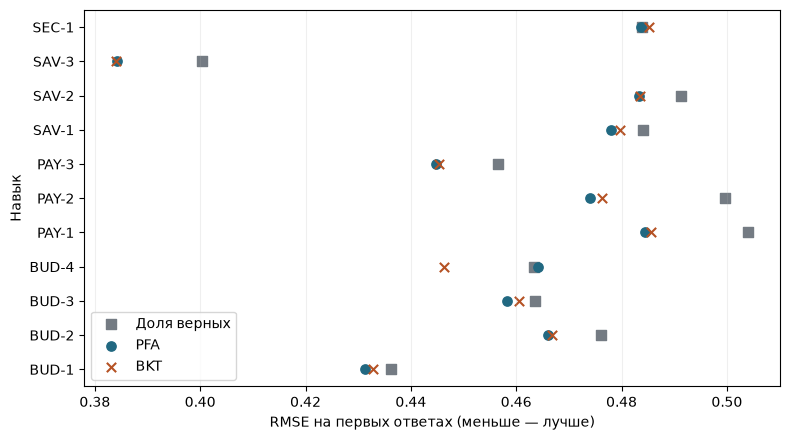

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, color, marker in [("rate", "#747b83", "s"), ("PFA", "#216881", "o"), ("BKT", "#b55224", "x")]:
    ax.scatter(skills[f"RMSE {m}"], skills.index, label={"rate": "Доля верных"}.get(m, m),
               marker=marker, s=45, color=color)
ax.set_xlabel("RMSE на первых ответах (меньше — лучше)")
ax.set_ylabel("Навык")
ax.legend()
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

## Интерпретация

По PAY-2 обе модели с историей улучшают прогноз остатка и сдачи. Для SEC-1 AUC близок к 0,5; этот навык представлен одной карточкой. У BUD-4 оценка перехода к освоению достигает верхней границы 0,999. Такой результат требует проверки на разнообразных заданиях до вывода о том, как быстро ребёнок учится.

В таблице ниже приведены 95%-е процентильные интервалы для разности RMSE при 2 000 парных бутстрэп-выборках из 60 тестовых детей. История каждого ребёнка выбирается целиком, параметры моделей фиксированы. Обе модели улучшают RMSE относительно доли верных; интервал для разницы между BKT и PFA включает ноль. Для демонстрации адаптивности можно использовать BKT, поскольку она явно обновляет состояние навыка. Проверка точности выполнена на синтетических ответах одного прогона и сама по себе не измеряет учебный эффект у детей.

In [5]:
ci = pd.DataFrame.from_dict(result["paired_rmse_ci95"], orient="index", columns=["2,5%", "97,5%"])
print(ci.round(5).to_string())
print("\nПараметры BKT по навыкам")
print(pd.DataFrame({s: v["BKT"] for s, v in result["models"].items()}).T.round(3).to_string())

                   2,5%    97,5%
BKT minus PFA  -0.00117  0.00136
BKT minus rate -0.01375 -0.00722
PFA minus rate -0.01329 -0.00793

Параметры BKT по навыкам
       p_init  p_learn  p_guess  p_slip
BUD-1   0.307    0.244    0.499   0.179
BUD-2   0.096    0.382    0.496   0.190
BUD-3   0.366    0.130    0.499   0.222
BUD-4   0.315    0.999    0.126   0.268
PAY-1   0.126    0.082    0.316   0.247
PAY-2   0.071    0.069    0.349   0.220
PAY-3   0.254    0.055    0.499   0.149
SAV-1   0.369    0.036    0.499   0.205
SAV-2   0.506    0.134    0.446   0.258
SAV-3   0.182    0.049    0.120   0.499
SEC-1   0.157    0.118    0.483   0.197


Границы поиска для p_init и p_learn — от 0,001 до 0,999, для p_guess и p_slip — от 0,001 до 0,499. Эти ограничения фиксируют интерпретацию состояний. Оценки на границе стоит перепроверить при изменении формата задания и на данных пилота.